## Instalação da biblioteca emoji para tratamento e remoção de emojis durante a limpeza textual.

In [13]:
!pip -q install emoji

## Importando as Bibliotecas

In [14]:
import kagglehub
import pandas as pd
import emoji
import re
import os
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras import regularizers
from sklearn.metrics import classification_report
from tensorflow.keras.layers import SpatialDropout1D, LayerNormalization

## Link do Dataset: [https://www.kaggle.com/datasets/kazanova/sentiment140](https://www.kaggle.com/datasets/kazanova/sentiment140)

## 1. Configurações e Hiperparâmetros

In [15]:
vocab_size = 20000
max_length = 60
batch_size = 128
epochs = 50

## 2. Carregamento e Preparação dos Dados

In [16]:
path = kagglehub.dataset_download("kazanova/sentiment140")
print("Path to dataset files:", path)

caminho_arquivo = os.path.join(path, 'training.1600000.processed.noemoticon.csv')

colunas = ['target', 'id', 'date', 'flag', 'user', 'text']
df = pd.read_csv(caminho_arquivo, encoding='latin-1', names=colunas)

Path to dataset files: /kaggle/input/datasets/kazanova/sentiment140


### Manter apenas as colunas relevantes

In [17]:
df = df[['text', 'target']]
df['target'] = df['target'].replace(4, 1)
df = df.dropna(subset=['target'])

tamanho_amostra_por_classe = 200000
df_negativo = df[df['target'] == 0].sample(n=tamanho_amostra_por_classe, random_state=42)
df_positivo = df[df['target'] == 1].sample(n=tamanho_amostra_por_classe, random_state=42)

df = pd.concat([df_negativo, df_positivo]).sample(frac=1, random_state=42).reset_index(drop=True)
print(f"Novo tamanho do dataset: {len(df)} registros ({tamanho_amostra_por_classe} de cada classe).")

Novo tamanho do dataset: 400000 registros (200000 de cada classe).


In [18]:
def limpar_texto(texto):
    texto = re.sub(r'http\S+', '', texto)
    texto = re.sub(r'@\w+', '', texto)
    texto = re.sub(r'#\w+', '', texto)
    texto = re.sub(r'[^a-zA-Z\s]', '', texto)
    texto = emoji.replace_emoji(texto, replace=" ")
    return texto.lower().strip()

df['text_clean'] = df['text'].apply(limpar_texto)

## 3. Tokenização e Preenchimento (Padding)

In [19]:
# Divisão em treino e teste (80% treino, 20% teste)
X_train, X_test, y_train, y_test = train_test_split(df['text'], df['target'], test_size=0.2, random_state=42, stratify=df['target'])

tokenizer = Tokenizer(num_words=vocab_size)
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(X_train_seq, maxlen=max_length, padding='pre')
X_test_pad = pad_sequences(X_test_seq, maxlen=max_length, padding='pre')

## 4. Arquitetura do Modelo LSTM

In [20]:
modelo = Sequential()
modelo.add(Embedding(input_dim=vocab_size, output_dim=128, input_length=max_length))
modelo.add(SpatialDropout1D(0.25)) # evitar overfitting nos embeddings

modelo.add(LSTM(units=128, kernel_regularizer=tf.keras.regularizers.l2(0.0001), return_sequences=True))
modelo.add(LayerNormalization())
modelo.add(Dropout(0.2))

modelo.add(LSTM(units=64, kernel_regularizer=tf.keras.regularizers.l2(0.0001), return_sequences=True))
modelo.add(LayerNormalization())
modelo.add(Dropout(0.2))

modelo.add(LSTM(units=64, kernel_regularizer=tf.keras.regularizers.l2(0.0001), return_sequences=True))
modelo.add(LayerNormalization())
modelo.add(Dropout(0.2))

modelo.add(LSTM(units=32, kernel_regularizer=tf.keras.regularizers.l2(0.0001), return_sequences=False))
modelo.add(LayerNormalization())
modelo.add(Dropout(0.2))

modelo.add(Dense(1, activation='sigmoid'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


## 5. Compilando o modelo para classificação Binaria

In [21]:
modelo.compile(
    loss='binary_crossentropy',
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    metrics=['accuracy']
)

modelo.build(input_shape=(None, max_length))
modelo.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 60, 128)        │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_1             │ (None, 60, 128)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ (None, 60, 128)        │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_4           │ (None, 60, 128)        │           256 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 60, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 60, 64)         │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_5           │ (None, 60, 64)         │           128 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_6 (LSTM)                   │ (None, 60, 64)         │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_6           │ (None, 60, 64)         │           128 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_7 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_7           │ (None, 32)             │            64 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,787,041 (10.63 MB)

 Trainable params: 2,787,041 (10.63 MB)

 Non-trainable params: 0 (0.00 B)

## 6. Treinamento do modelo

In [22]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=8,
    restore_best_weights=True 
)
historico = modelo.fit(
    X_train_pad, 
    y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_split=0.2,
    callbacks=[early_stop]
)

Epoch 1/50
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 49s 22ms/step - accuracy: 0.7674 - loss: 0.5112 - val_accuracy: 0.8041 - val_loss: 0.4480
Epoch 2/50
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 44s 22ms/step - accuracy: 0.8188 - loss: 0.4184 - val_accuracy: 0.8073 - val_loss: 0.4341
Epoch 3/50
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 44s 22ms/step - accuracy: 0.8346 - loss: 0.3824 - val_accuracy: 0.8030 - val_loss: 0.4493
Epoch 4/50
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 44s 22ms/step - accuracy: 0.8499 - loss: 0.3553 - val_accuracy: 0.8012 - val_loss: 0.4489
Epoch 5/50
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 44s 22ms/step - accuracy: 0.8615 - loss: 0.3313 - val_accuracy: 0.7997 - val_loss: 0.5151
Epoch 6/50
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 44s 22ms/step - accuracy: 0.8714 - loss: 0.3104 - val_accuracy: 0.7978 - val_loss: 0.4961
Epoch 7/50
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 44s 22ms/step - accuracy: 0.8794 - loss: 0.2938 - val_accuracy: 0.7971 - val_loss: 0.5365
Epoch 8/50
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 44s 22ms/step - accuracy: 0.8881 -

## 7. Visualização das Predições

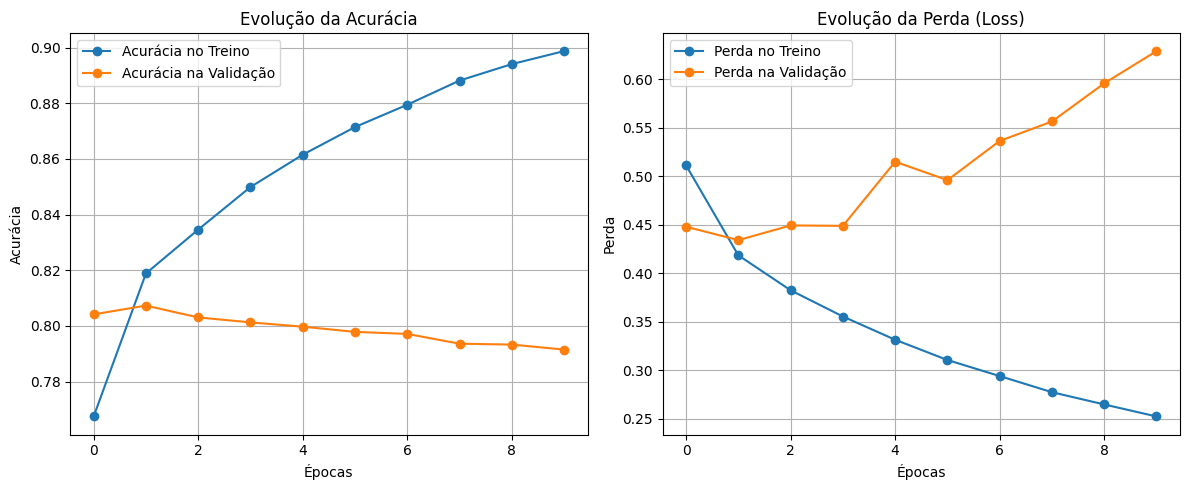

In [23]:
plt.figure(figsize=(12, 5))

# Gráfico de Acurácia
plt.subplot(1, 2, 1)
plt.plot(historico.history['accuracy'], label='Acurácia no Treino', marker='o')
plt.plot(historico.history['val_accuracy'], label='Acurácia na Validação', marker='o')
plt.title('Evolução da Acurácia')
plt.xlabel('Épocas')
plt.ylabel('Acurácia')
plt.legend()
plt.grid(True)

# Gráfico de Perda (Loss)
plt.subplot(1, 2, 2)
plt.plot(historico.history['loss'], label='Perda no Treino', marker='o')
plt.plot(historico.history['val_loss'], label='Perda na Validação', marker='o')
plt.title('Evolução da Perda (Loss)')
plt.xlabel('Épocas')
plt.ylabel('Perda')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## 8. Avaliação do modelo

In [24]:
y_pred_prob = modelo.predict(X_test_pad)
y_pred = (y_pred_prob > 0.5).astype(int).flatten()

y_true = y_test

class_names = ['Negativo', 'Positivo']

relatorio = classification_report(y_true, y_pred, target_names=class_names, zero_division=0)
print("Relatório de Classificação:\n")
print(relatorio)

2500/2500 ━━━━━━━━━━━━━━━━━━━━ 15s 6ms/step
Relatório de Classificação:

              precision    recall  f1-score   support

    Negativo       0.82      0.77      0.80     40000
    Positivo       0.79      0.83      0.81     40000

    accuracy                           0.80     80000
   macro avg       0.80      0.80      0.80     80000
weighted avg       0.80      0.80      0.80     80000



## 9. Matriz de Confusão

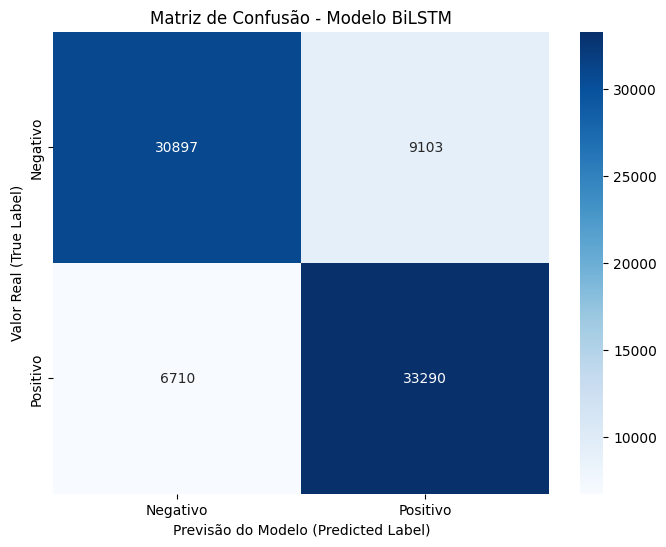

In [25]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, 
            yticklabels=class_names)

plt.title('Matriz de Confusão - Modelo BiLSTM')
plt.ylabel('Valor Real (True Label)')
plt.xlabel('Previsão do Modelo (Predicted Label)')
plt.show()